In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
path = '/content/drive/MyDrive/Colab Notebooks/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(path)
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(7043, 21)


In [2]:
# Việc 1: TotalCharges từ chữ thành số
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Số ô trống:', df['TotalCharges'].isna().sum())
print('Tenure của các khách đó:', df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Việc 2: xoá mã khách
df = df.drop(columns=['customerID'])

# Việc 3: Yes/No thành 1/0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

print(df.shape)
print(df.dtypes['TotalCharges'], df['Churn'].unique())

Số ô trống: 11
Tenure của các khách đó: [0]
(7043, 20)
float64 [0 1]


In [3]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [4]:
for col in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']:
    print(df.groupby(col)['Churn'].mean().sort_values(ascending=False).round(3))
    print()

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: Churn, dtype: float64



In [5]:
print(df.dtypes)
print()
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True))

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


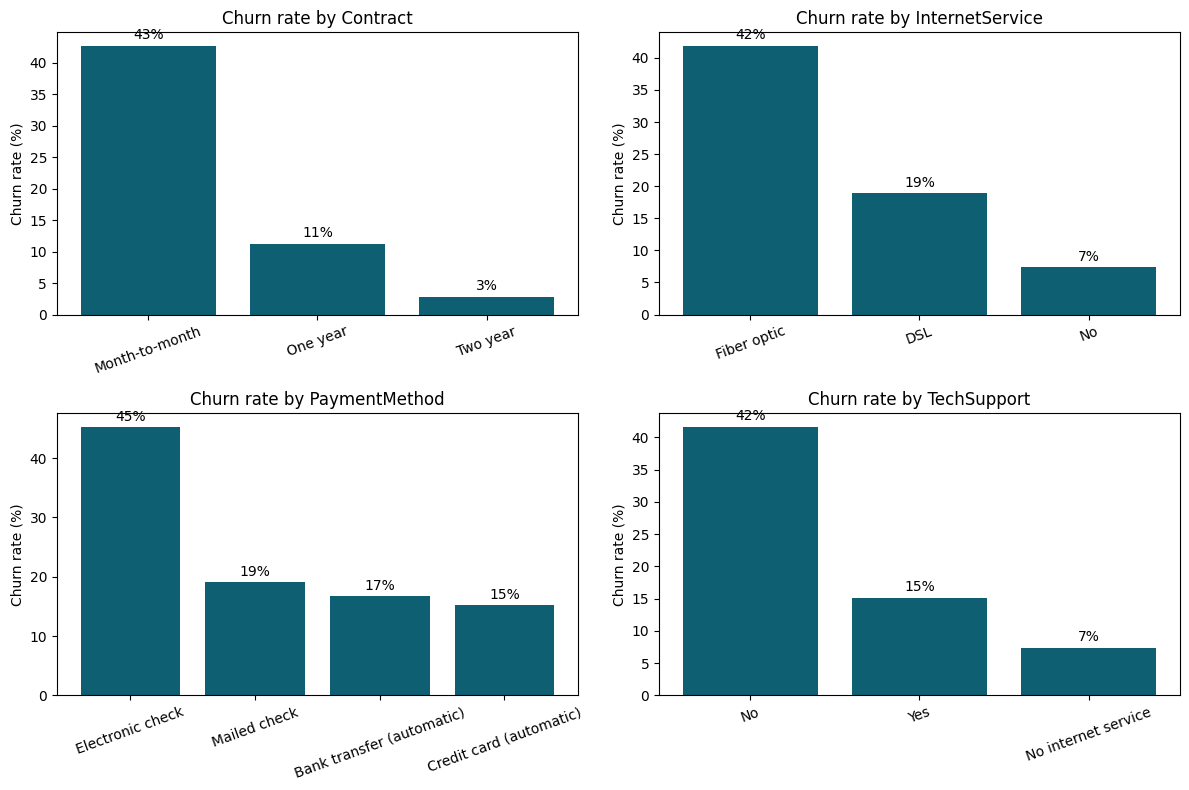

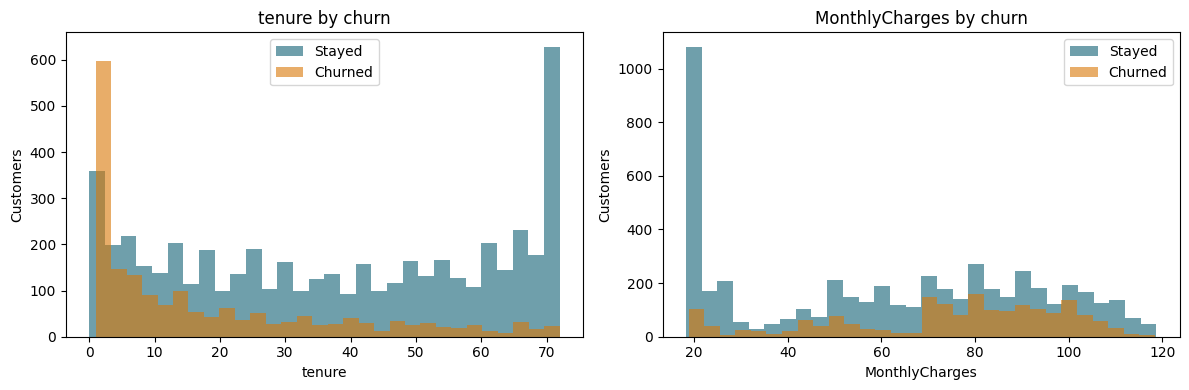

,Churn
tenure_group,
0-12,47.4
13-24,28.7
25-48,20.4
49-72,9.5


In [6]:
import matplotlib.pyplot as plt
import os

# Thư mục lưu ảnh trong Google Drive (để không bị mất khi tắt Colab)
img_dir = '/content/drive/MyDrive/Colab Notebooks/images'
os.makedirs(img_dir, exist_ok=True)

cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))   # khung 2 hàng × 2 cột = 4 biểu đồ

for ax, col in zip(axes.flat, cols):
    rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False) * 100
    ax.bar(rate.index, rate.values, color='#0F5F73')
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.tick_params(axis='x', rotation=20)          # nghiêng chữ cho khỏi đè nhau
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f'{v:.0f}%', ha='center')  # ghi số % trên đầu mỗi cột

plt.tight_layout()
plt.savefig(f'{img_dir}/churn_rate_by_category.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))   # 1 hàng × 2 biểu đồ

for ax, col in zip(axes, ['tenure', 'MonthlyCharges']):
    ax.hist(df.loc[df['Churn'] == 0, col], bins=30, alpha=0.6, label='Stayed', color='#0F5F73')
    ax.hist(df.loc[df['Churn'] == 1, col], bins=30, alpha=0.6, label='Churned', color='#D97706')
    ax.set_title(f'{col} by churn')
    ax.set_xlabel(col)
    ax.set_ylabel('Customers')
    ax.legend()

plt.tight_layout()
plt.savefig(f'{img_dir}/tenure_monthly_by_churn.png', dpi=150)
plt.show()
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                            labels=['0-12', '13-24', '25-48', '49-72'])
(df.groupby('tenure_group', observed=True)['Churn'].mean() * 100).round(1)

In [7]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['tenure_group'])   # xoá cột phụ tạo ở bước 4b

X = df.drop(columns=['Churn'])            # 19 cột thông tin
y = df['Churn']                           # cột đáp án

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Tỷ lệ rời bỏ train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train: (5634, 19)  Test: (1409, 19)
Tỷ lệ rời bỏ train: 0.265  test: 0.265


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

baseline = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000)),
])

baseline.fit(X_train, y_train)
print('Đã huấn luyện xong!')

from sklearn.metrics import classification_report, confusion_matrix

y_pred = baseline.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Đã huấn luyện xong!
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

[[926 109]
 [165 209]]


In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()   # số khách ở lại / số khách rời bỏ
print('Tỷ lệ ở lại / rời bỏ:', round(ratio, 2))

models = {
    'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=ratio, eval_metric='logloss', random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=['precision', 'recall', 'f1', 'roc_auc'])
    rows.append({'model': name,
                 **{k.replace('test_', ''): v.mean().round(3)
                    for k, v in s.items() if k.startswith('test_')}})
    print('Xong', name)

results = pd.DataFrame(rows).sort_values('f1', ascending=False)
results


Tỷ lệ ở lại / rời bỏ: 2.77
Xong LogReg
Xong DecisionTree
Xong RandomForest
Xong XGBoost


,model,precision,recall,f1,roc_auc
3,XGBoost,0.533,0.773,0.631,0.844
2,RandomForest,0.557,0.724,0.629,0.845
0,LogReg,0.517,0.801,0.628,0.846
1,DecisionTree,0.510,0.777,0.615,0.827


In [10]:

for name in ['LogReg', 'RandomForest', 'XGBoost']:
    pipe = Pipeline([('prep', preprocess), ('model', models[name])])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1', return_train_score=True)
    print(f"{name:13s}  F1 train = {s['train_score'].mean():.3f}   "
          f"F1 val = {s['test_score'].mean():.3f} ± {s['test_score'].std():.3f}")

LogReg         F1 train = 0.634   F1 val = 0.628 ± 0.023
RandomForest   F1 train = 0.751   F1 val = 0.629 ± 0.018
XGBoost        F1 train = 0.721   F1 val = 0.631 ± 0.015


In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

best = Pipeline([('prep', preprocess), ('model', models['LogReg'])])

# Xác suất rời bỏ của từng khách train, mỗi khách được dự đoán khi nó đang làm "val"
proba_oof = cross_val_predict(best, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba_oof >= t).astype(int)
    rows.append({'threshold': t,
                 'precision': round(precision_score(y_train, pred), 3),
                 'recall': round(recall_score(y_train, pred), 3),
                 'f1': round(f1_score(y_train, pred), 3),
                 'flagged': int(pred.sum())})
pd.DataFrame(rows)


,threshold,precision,recall,f1,flagged
0,0.3,0.424,0.926,0.582,3263
1,0.4,0.471,0.866,0.610,2751
2,0.5,0.517,0.801,0.628,2318
3,0.6,0.571,0.719,0.636,1884
4,0.7,0.629,0.593,0.611,1410


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
best_thr = 0.5
# 1. Huấn luyện mô hình đã chọn trên TOÀN BỘ tập train
best.fit(X_train, y_train)

# 2. Dự đoán xác suất cho tập test (1 409 khách mô hình chưa từng thấy)
proba_test = best.predict_proba(X_test)[:, 1]

# 3. Áp ngưỡng đã chọn từ validation (KHÔNG chọn lại ở đây)
pred_test = (proba_test >= best_thr).astype(int)

# 4. Báo cáo
print('Ngưỡng:', best_thr)
print(confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test, digits=3))
print('ROC-AUC:', round(roc_auc_score(y_test, proba_test), 3))

Ngưỡng: 0.5
[[747 288]
 [ 81 293]]
              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

ROC-AUC: 0.842


tenure             0.1537
InternetService    0.0427
MonthlyCharges     0.0399
Contract           0.0393
TotalCharges       0.0114
StreamingMovies    0.0046
OnlineSecurity     0.0042
StreamingTV        0.0041
dtype: float64


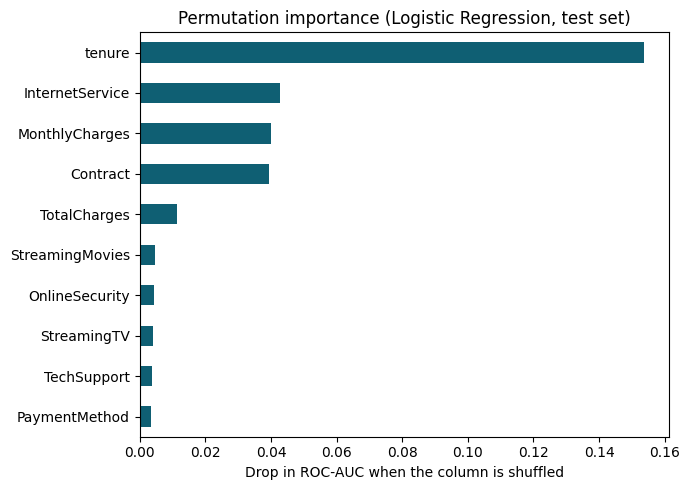

In [13]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

imp = permutation_importance(best, X_test, y_test,
                             scoring='roc_auc', n_repeats=10, random_state=42)

imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
print(imp_s.sort_values(ascending=False).head(8).round(4))

imp_s.tail(10).plot.barh(figsize=(7, 5), color='#0F5F73')
plt.xlabel('Drop in ROC-AUC when the column is shuffled')
plt.title('Permutation importance (Logistic Regression, test set)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/images/feature_importance.png', dpi=150)
plt.show()

tenure             0.1537
InternetService    0.0427
MonthlyCharges     0.0399
Contract           0.0393
TotalCharges       0.0114
StreamingMovies    0.0046
OnlineSecurity     0.0042
StreamingTV        0.0041
dtype: float64


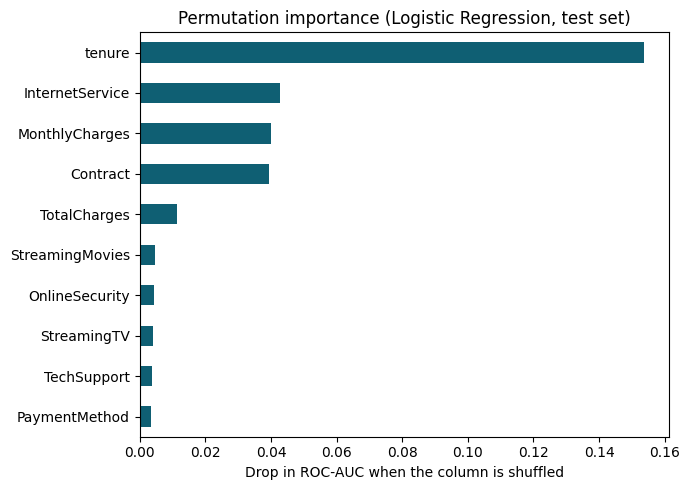

In [14]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

imp = permutation_importance(best, X_test, y_test,
                             scoring='roc_auc', n_repeats=10, random_state=42)

imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
print(imp_s.sort_values(ascending=False).head(8).round(4))

imp_s.tail(10).plot.barh(figsize=(7, 5), color='#0F5F73')
plt.xlabel('Drop in ROC-AUC when the column is shuffled')
plt.title('Permutation importance (Logistic Regression, test set)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/images/feature_importance.png', dpi=150)
plt.show()

In [15]:
print(df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False).round(3))

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64
